# 입문자를 위한 차원 축소 해체법

## Loading Dependencies and Data

In [7]:
#Dependencies
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.datasets import load_breast_cancer #Loading the full DataSet From Sklearn Library

#Breast cancer dataset
cancer= load_breast_cancer()
(X_canc, y_canc)= load_breast_cancer(return_X_y=True)  #X_canc, y_canc = cancer.data, cancer.target와 같은 코드


## Helper Functions

In [ ]:
#A Function to Plot labelled Scatter Plot
def plot_labelled_scatter(X, y, class_labels, s):
    num_labels= len(class_labels)

    x_min, x_max= X[:, 0].min()-1,  X[:, 0].max()+1
    y_min, y_max= X[:, 1].min()-1,  X[:, 1].max()+1

    marker_array= ['o', '^', '*']
    color_array= ['#FFFF00', '#00AAFF', '#000000', '#FF00AA']
    cmap_bold= ListedColormap(color_array) #ListedColormap(): 지정한 색목록을 컬러맵 만들어줌
    bnorm= BoundaryNorm(np.arange(0, num_labels+1, 1), ncolors=num_labels) 
    # BoundaryNorm (): 경계값을 기준으로 데이터를 구간별로 나누고, 각 구간에 색을 지정.  
    # ncolors=num_labels : 사용할 색의 개수 지정. 
    plt.figure(figsize=s) #그래프의 크기 (가로, 세로)

    plt.scatter(X[:, 0], X[:, 1], s=80, c=y, cmap=cmap_bold, norm=bnorm, alpha=0.4, edgecolors='black', lw=1)
    #s=size, norm은 데이터 값을 색상에 대응시키는 기준(normalization), lw=linewidth
    sp=plt.gca().spines #get current axis. 현재 그리고 있는 그래프의 좌표축을 가져옴.
    sp['top'].set_visible(False) #위쪽 테두리 제거
    sp['right'].set_visible(False) #오른쪽 테두리 제거 

    plt.grid(which='both', color= 'lightslategrey', alpha=0.3)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)


    # legend 추가 
    h=[] #legend 항목을 만들 빈 리스트 
    for c in range(0, num_labels):
        h.append(mpatches.Patch(color=color_array[c], label=class_labels[c])) #색깔 네모와 이름

    plt.legend(handles=h, fontsize=15, frameon=False) #handles는 범례항목 지정. 


## 1. PCA 

### Using PCA to find the first two Principal Components of the Breast Cancer Dataset

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#PCA 적용 전, 각 피처 평균0, 분산1로 표준화
canc_norm= StandardScaler().fit(X_canc).transform(X_canc)

pca= PCA(n_components=2).fit(canc_norm) #Fitting PCA with 2 components

canc_pca= pca.transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before PCA : {0}\n\nNumber of Features in Breast Cancer DataSet After PCA : {1}'.format(X_canc.shape[1],canc_pca.shape[1]))

Number of Features in Breat Cancer DataSet Before PCA : 30

Number of Features in Breast Cancer DataSet After PCA : 2


### Plotting the PCA-Transformed Version of the Breast Cancer Dataset

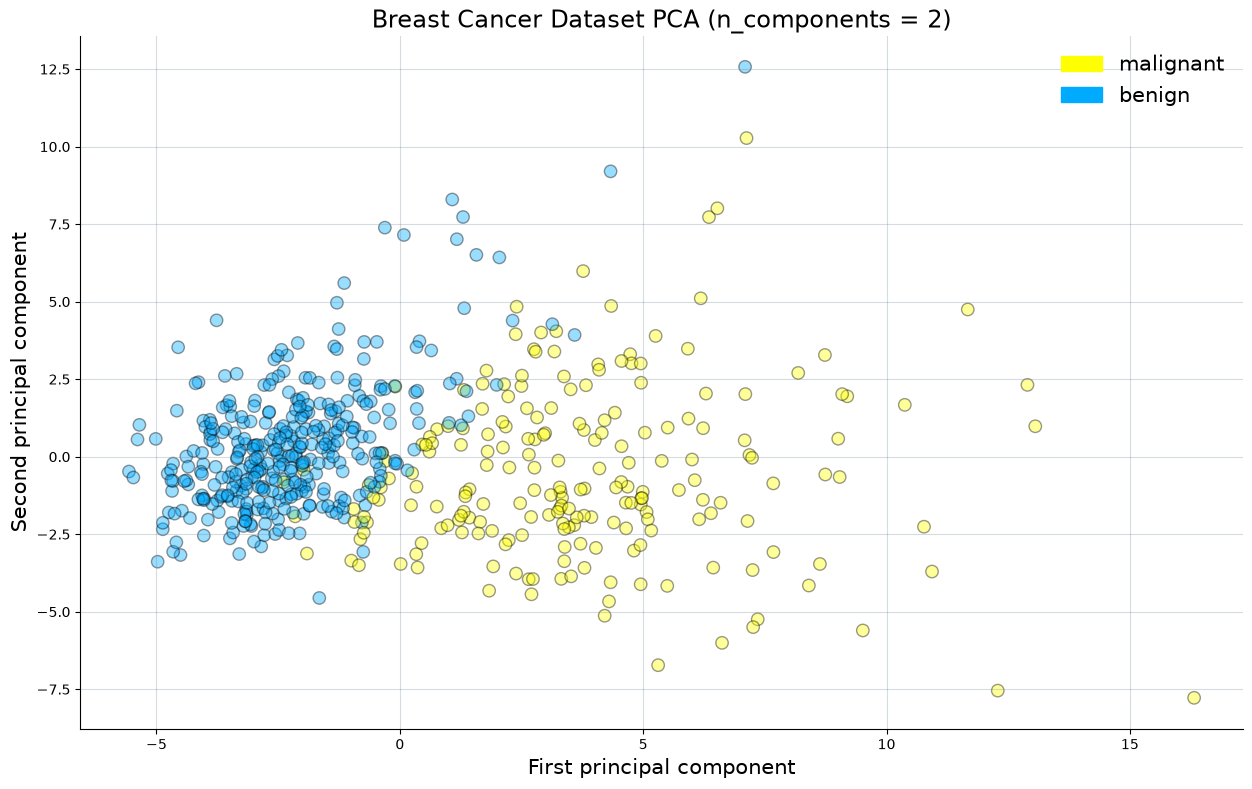

In [10]:
plot_labelled_scatter(canc_pca, y_canc, ['malignant', 'benign'], (15,9)) #Using Helper Function

#Labelling
plt.xlabel('First principal component',fontsize=15)
plt.ylabel('Second principal component',fontsize=15)
plt.title('Breast Cancer Dataset PCA (n_components = 2)',fontsize=17);

### Using PCA to get feature Co-Relation Between the Initial 30 Features

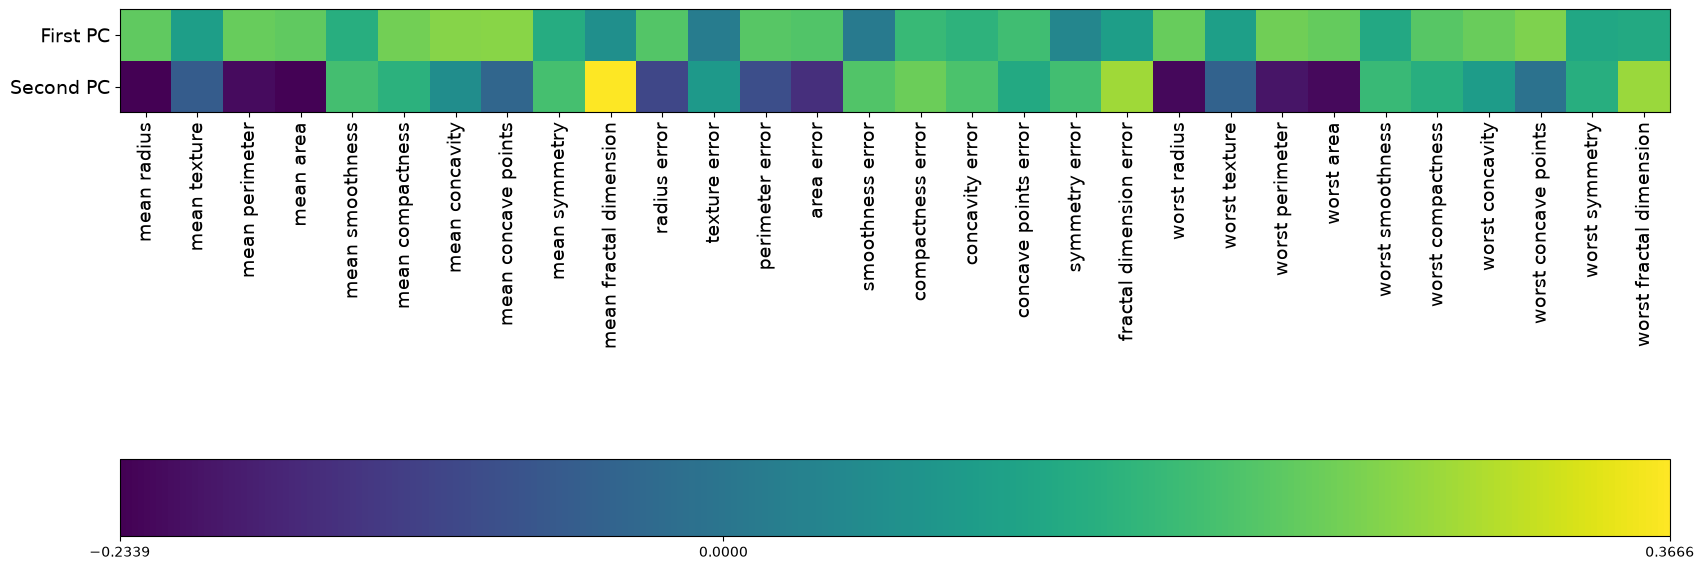

In [ ]:
#pca의 .components 속성 : 행은 주성분, 열은 원래 피처인 2차원 행렬. 원래 특성들이 각 주성분을 만드는 데 각각 얼마나, 어떤 방향으로 기여했는지 나타냄.
fig= plt.figure(figsize=(20,9)) #가로 20 세로 9 그림생성
plt.imshow(pca.components_, interpolation='none', cmap= 'viridis') #2차원 행렬을 시각화(히트맵 생성)
feature_names= list(cancer.feature_names)

plt.gca().set_xticks(np.arange(len(feature_names))); #0~29 눈금. 각 피처의 위치에 눈금표시
plt.gca().set_yticks(np.arange(2)); #0,1에 눈금
plt.gca().set_xticklabels(feature_names, rotation=90, fontsize=14);
plt.gca().set_yticklabels(['First PC', 'Second PC'], fontsize=14);

plt.colorbar(orientation= 'horizontal', #가로 방향 
            ticks=[pca.components_.min(),0,pca.components_.max()], #최솟값, 최댓값, 0에 눈금 표시
            pad=0.5); #heatmap과 colorbar 사이 간격 

#PC1은 모두 양수. 모든 특성 사이에 전반적인 양의 상관관계 
#PC2는 양수, 음수 섞임. 일부 특성 그루은 다른 그룹과 반대 방향으로 변함. 
#PC1, PC2는 서로 다른 변화 패턴을 나타낸다. 

## 2. Multi-Dimensional Scaling : (MDS)

1. Manifold Learning (매니폴드 학습) 
- 목적: 고차원 데이터에서 저차원 구조를 찾아 시각화하는 비지도 학습 방법
- 고차원 공간 안에 존재하는 저차원 구조를 Manifold(매니폴드) 라고 함.
- PCA의 한계: 데이터의 복잡하게 휘어진 구조를 제대로 찾아내지 못함.
-> 해결 방법: Manifold Learning을 활용하여 데이터의 숨겨진 저차원 구조를 발견함. 
-> 대표적인 방법: MDS 

2. MDS의 목표 : 고차원 데이터셋을 시각화하고, 이를 저차원 공간(2차원)으로 투영. 
-원래 데이터 공간에서 점들이 얼마나 서로 가까이 있는지에 대한 정보를 최대한 보존하는 방식 사용. 
-> 고차원 데이터에서 군집이 형성되는 패턴을 발견하고 시각화 가능. 

### Using MDS on the Breast Cancer Dataset

c:\Users\0510n\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


Number of Features in Breat Cancer DataSet Before MDS : 30

Number of Features in Breast Cancer DataSet After MDS : 2


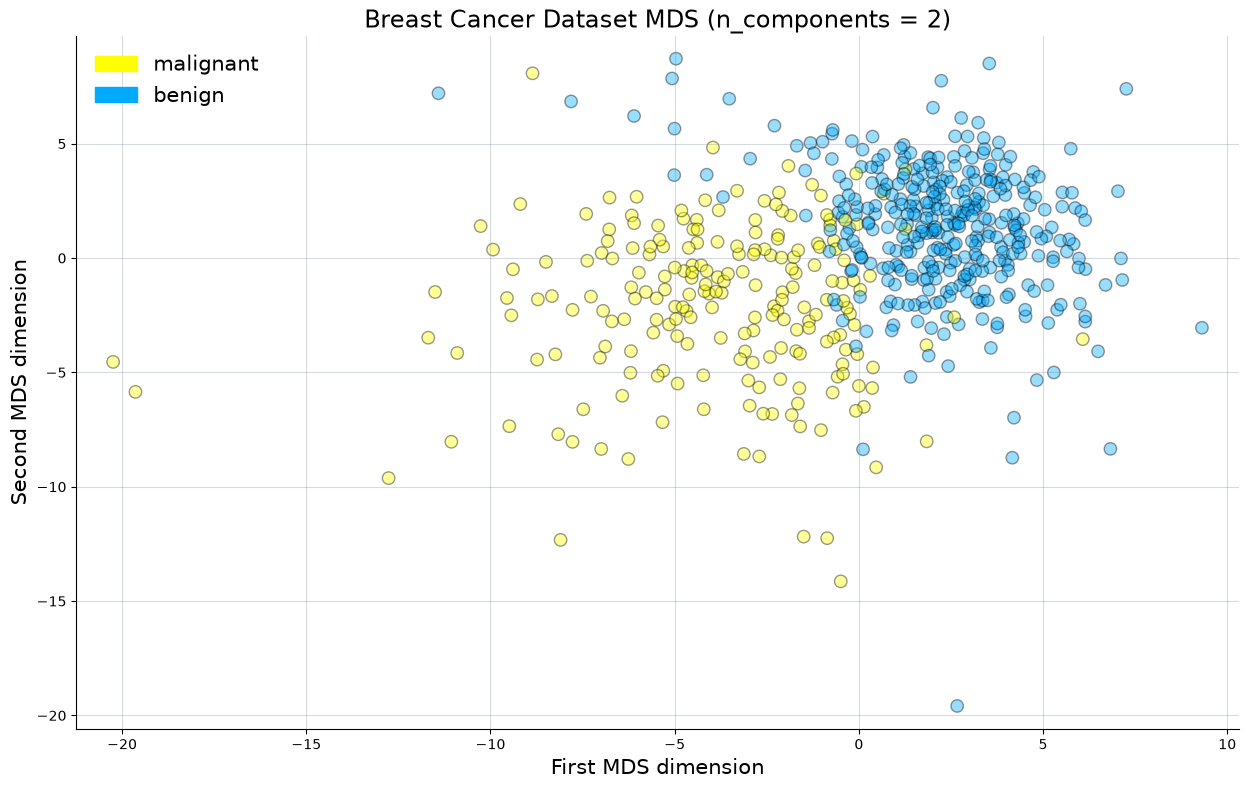

In [16]:
from sklearn.manifold import MDS

mds= MDS(n_components=2, random_state=2)

canc_mds= mds.fit_transform(canc_norm)
print('Number of Features in Breat Cancer DataSet Before MDS : {}\n\nNumber of Features in Breast Cancer DataSet After MDS : {}'
      .format(X_canc.shape[1],canc_mds.shape[1]))

plot_labelled_scatter(canc_mds, y_canc, ['malignant', 'benign'], (15,9))

plt.xlabel('First MDS dimension',fontsize=15)
plt.ylabel('Second MDS dimension',fontsize=15)
plt.title('Breast Cancer Dataset MDS (n_components = 2)',fontsize=17);


## 3. T-distributed Stochastic Neighbor Embedding (t-SNE)

 Manifold Learning (매니폴드 학습) 알고리즘 중 하나임. 
- 역시 고차원 데이터를 2차원으로 축소하여 시각화
- 원래 데이터에서 가까웠던 점들이 2차원에서도 가깝게 나타나도록 함.
- 특히 가까운 이웃 간 관계를 보존하는 데 훨씬 더 큰 가중치를 부여. 
- 위와 방법은 같다

### Using T-SNE on the Breast Cancer Dataset

Number of Features in Breat Cancer DataSet Before T-SNE : 30

Number of Features in Breast Cancer DataSet After T-SNE : 2


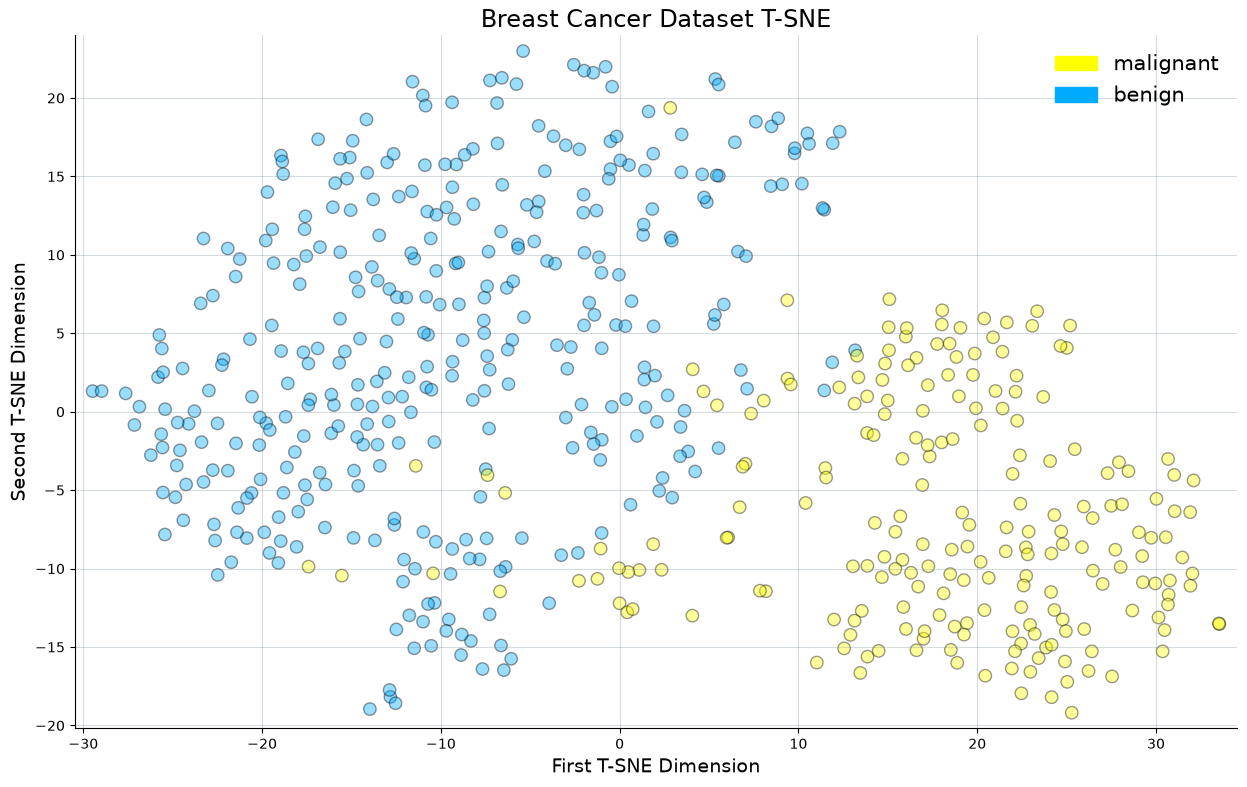

In [17]:
from sklearn.manifold import TSNE

tsne= TSNE(random_state=42)

canc_tsne= tsne.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before T-SNE : {}\n\nNumber of Features in Breast Cancer DataSet After T-SNE : {}'.format(X_canc.shape[1], canc_tsne.shape[1]))

plot_labelled_scatter(canc_tsne, y_canc, ['malignant', 'benign'], (15,9))

plt.xlabel('First T-SNE Dimension',fontsize=14)
plt.ylabel('Second T-SNE Dimension',fontsize=14)
plt.title('Breast Cancer Dataset T-SNE',fontsize=17);